# COS802 — 01 GQA Dataset Setup

This notebook constructs a **crop-suitable GQA subset** for the OPSD experiment.

In [ ]:
%pip -q install -U pandas numpy scikit-learn Pillow tqdm matplotlib requests remotezip


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
from pathlib import Path
import json, re, zipfile, shutil, random
import numpy as np
import pandas as pd
import requests
from PIL import Image, ImageOps
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

def locate_src_root():
    cwd = Path.cwd().resolve()
    for base in [cwd, *cwd.parents]:
        candidate = base / "src"
        if candidate.is_dir():
            return candidate.resolve()
        if base.name == "src" and (base / "data").exists():
            return base.resolve()
    return (cwd / "src").resolve()

ROOT = locate_src_root()
DATA = ROOT / "data"
RAW = DATA / "raw" / "gqa"
IMAGES = DATA / "images"
CROPS = DATA / "crops"
PROCESSED = DATA / "processed"
RESULTS = ROOT / "results"

for p in [RAW, IMAGES, CROPS, PROCESSED, RESULTS]:
    p.mkdir(parents=True, exist_ok=True)

print("src root:", ROOT)
print("GQA raw:", RAW)
print("Images:", IMAGES)
print("Crops:", CROPS)
print("Processed:", PROCESSED)


src root: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src
GQA raw: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa
Images: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/images
Crops: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/crops
Processed: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/processed


In [31]:
SEED = 42

TARGET_QA = 5_000
CANDIDATE_QA = 12_000

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TEST_FRAC = 0.15

MAX_QA_PER_IMAGE = 3

# Crop-suitable questions should stay fairly local.
MAX_GROUNDED_OBJECTS = 2

MIN_CROP_AREA_RATIO = 0.02
MAX_CROP_AREA_RATIO = 0.50

# Padding can enlarge the final crop slightly.
MAX_FINAL_CROP_AREA_RATIO = 0.55

MIN_CROP_SIDE = 24
CROP_PADDING = 0.12

# Reuse the images you already downloaded.
# If the local filtered pool is too small, the notebook stops and
# tells you to set this to False if you want to top up from GQA.
REUSE_DOWNLOADED_IMAGES_ONLY = True

# GQA question types that are intrinsically unsuitable for a
# local privileged crop.
UNSAFE_SEMANTIC_TYPES = {
    "rel",
    "relation",
    "global",
}

UNSAFE_STRUCTURAL_TYPES = {
    "compare",
}

# Detailed-type safety net. Exact known types plus substring checks
# below catch positional/relational/comparison variants.
EXCLUDED_DETAILED_TYPES = {
    "positionQuery",
    "positionChoose",
    "positionVerify",
    "positionVerifyC",
    "relChooser",
    "existRelS",
    "existRel",
    "queryRel",
    "verifyRel",
    "chooseRel",
    "chooseObjRel",
    "compare",
    "common",
    "twoSame",
    "twoDiff",
    "allSame",
    "allDiff",
}

# Program operations that imply the answer depends on relations
# between entities or comparison/global reasoning rather than a
# locally answerable object/attribute crop.
UNSAFE_PROGRAM_BASE_OPS = {
    "relate",
    "compare",
    "common",
    "same",
    "different",
}

# Last-resort English safety net. Program/type filtering is primary.
SPATIAL_TEXT_PATTERNS = [
    r"\bleft of\b",
    r"\bright of\b",
    r"\bto the left\b",
    r"\bto the right\b",
    r"\bin front of\b",
    r"\bbehind\b",
    r"\babove\b",
    r"\bbelow\b",
    r"\bunder\b",
    r"\bover\b",
    r"\bnext to\b",
    r"\bbetween\b",
    r"\bnear\b",
    r"\bfar from\b",
    r"\bclosest to\b",
    r"\bfarthest from\b",
]

GQA_IMAGES_URL = "https://downloads.cs.stanford.edu/nlp/data/gqa/images.zip"
GQA_IMAGES_ZIP = RAW / "images.zip"

random.seed(SEED)
np.random.seed(SEED)

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9

print("Target QA:", TARGET_QA)
print("Candidate QA:", CANDIDATE_QA)
print("Reuse downloaded images only:", REUSE_DOWNLOADED_IMAGES_ONLY)
print("Max grounded objects:", MAX_GROUNDED_OBJECTS)
print("Crop area range:", MIN_CROP_AREA_RATIO, "to", MAX_CROP_AREA_RATIO)
print("Final padded crop max:", MAX_FINAL_CROP_AREA_RATIO)


Target QA: 5000
Candidate QA: 12000
Reuse downloaded images only: True
Max grounded objects: 2
Crop area range: 0.02 to 0.5
Final padded crop max: 0.55


## Locate manually downloaded annotations

Place the extracted files anywhere under `src/data/raw/gqa/`:

- `train_balanced_questions.json`
- `val_balanced_questions.json`
- `train_sceneGraphs.json`
- `val_sceneGraphs.json`


In [32]:
def find_file(root, filename):
    matches = list(Path(root).rglob(filename))
    return matches[0] if matches else None

required_files = {
    "train_questions": "train_balanced_questions.json",
    "val_questions": "val_balanced_questions.json",
    "train_scene_graphs": "train_sceneGraphs.json",
    "val_scene_graphs": "val_sceneGraphs.json",
}

located = {
    key: find_file(RAW, filename)
    for key, filename in required_files.items()
}

missing = {
    key: filename
    for key, filename in required_files.items()
    if located[key] is None
}

if missing:
    raise FileNotFoundError(
        "Missing GQA files under "
        f"{RAW}:\n"
        + "\n".join(f"- {filename}" for filename in missing.values())
    )

TRAIN_Q = located["train_questions"]
VAL_Q = located["val_questions"]
TRAIN_SG = located["train_scene_graphs"]
VAL_SG = located["val_scene_graphs"]

print("Train questions:", TRAIN_Q)
print("Val questions:", VAL_Q)
print("Train scene graphs:", TRAIN_SG)
print("Val scene graphs:", VAL_SG)


Train questions: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/questions1.2/train_balanced_questions.json
Val questions: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/questions1.2/val_balanced_questions.json
Train scene graphs: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/sceneGraphs/train_sceneGraphs.json
Val scene graphs: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/sceneGraphs/val_sceneGraphs.json


In [33]:
def load_json(path):
    print("Loading:", path)
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

train_questions = load_json(TRAIN_Q)
val_questions = load_json(VAL_Q)
train_scene_graphs = load_json(TRAIN_SG)
val_scene_graphs = load_json(VAL_SG)

questions = {}
for qid, q in train_questions.items():
    item = dict(q)
    item["_source_split"] = "train"
    questions[str(qid)] = item

for qid, q in val_questions.items():
    item = dict(q)
    item["_source_split"] = "val"
    questions[str(qid)] = item

scene_graphs = {**train_scene_graphs, **val_scene_graphs}

print("Balanced questions:", f"{len(questions):,}")
print("Scene graphs:", f"{len(scene_graphs):,}")


Loading: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/questions1.2/train_balanced_questions.json
Loading: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/questions1.2/val_balanced_questions.json
Loading: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/sceneGraphs/train_sceneGraphs.json
Loading: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/raw/gqa/sceneGraphs/val_sceneGraphs.json
Balanced questions: 1,075,062
Scene graphs: 85,638


## Build grounded candidate questions

Grounding still uses only the **question-side annotations and semantic program object IDs**. Answer/full-answer annotations are not used to construct the crop.

Each candidate also stores its GQA semantic program so the next stage can determine whether the question is suitable for a local privileged crop.


In [34]:
OBJECT_ID_RE = re.compile(r"\((\d+)\)")

def extract_question_grounded_ids(question):
    object_ids = set()

    question_ann = question.get("annotations", {}).get("question", {})
    if isinstance(question_ann, dict):
        for value in question_ann.values():
            if value is not None:
                object_ids.add(str(value))

    semantic = question.get("semantic", [])
    if isinstance(semantic, list):
        for step in semantic:
            argument = str(step.get("argument", ""))
            for match in OBJECT_ID_RE.findall(argument):
                object_ids.add(str(match))

    return sorted(object_ids)


def semantic_program_metadata(question):
    semantic = question.get("semantic", [])

    if not isinstance(semantic, list):
        return [], [], []

    operations = []
    base_operations = []
    arguments = []

    for step in semantic:
        operation = str(step.get("operation", "")).strip()
        argument = str(step.get("argument", "")).strip()

        operations.append(operation)
        arguments.append(argument)

        # GQA operations can be things such as "filter color".
        # The first token is the high-level operator.
        base_operation = (
            operation.split()[0].lower()
            if operation
            else ""
        )
        base_operations.append(base_operation)

    return operations, base_operations, arguments


def object_xyxy(obj):
    x1 = float(obj["x"])
    y1 = float(obj["y"])
    return [x1, y1, x1 + float(obj["w"]), y1 + float(obj["h"])]


def union_boxes(boxes):
    return [
        min(b[0] for b in boxes),
        min(b[1] for b in boxes),
        max(b[2] for b in boxes),
        max(b[3] for b in boxes),
    ]


def box_area_ratio(box, width, height):
    x1, y1, x2, y2 = box
    area = max(0, x2 - x1) * max(0, y2 - y1)
    total = width * height
    return area / total if total > 0 else 0.0


rows = []
reject_counts = {
    "missing_scene_graph": 0,
    "no_grounding": 0,
    "too_many_objects": 0,
    "missing_object": 0,
    "invalid_box": 0,
    "crop_too_small": 0,
    "crop_too_large": 0,
}

for qa_id, question in tqdm(
    questions.items(),
    total=len(questions),
    desc="Grounding GQA questions",
):
    image_id = str(question.get("imageId", ""))
    graph = scene_graphs.get(image_id)

    if graph is None:
        reject_counts["missing_scene_graph"] += 1
        continue

    object_ids = extract_question_grounded_ids(question)

    if not object_ids:
        reject_counts["no_grounding"] += 1
        continue

    if len(object_ids) > MAX_GROUNDED_OBJECTS:
        reject_counts["too_many_objects"] += 1
        continue

    graph_objects = graph.get("objects", {})

    if not all(oid in graph_objects for oid in object_ids):
        reject_counts["missing_object"] += 1
        continue

    width = int(graph["width"])
    height = int(graph["height"])

    boxes = []
    valid = True

    for oid in object_ids:
        try:
            box = object_xyxy(graph_objects[oid])
        except Exception:
            valid = False
            break

        x1, y1, x2, y2 = box

        if x2 <= x1 or y2 <= y1:
            valid = False
            break

        boxes.append(box)

    if not valid:
        reject_counts["invalid_box"] += 1
        continue

    union = union_boxes(boxes)
    ratio = box_area_ratio(union, width, height)

    crop_w = union[2] - union[0]
    crop_h = union[3] - union[1]

    if (
        crop_w < MIN_CROP_SIDE
        or crop_h < MIN_CROP_SIDE
        or ratio < MIN_CROP_AREA_RATIO
    ):
        reject_counts["crop_too_small"] += 1
        continue

    if ratio > MAX_CROP_AREA_RATIO:
        reject_counts["crop_too_large"] += 1
        continue

    objects = [
        graph_objects[oid].get("name", "")
        for oid in object_ids
    ]

    types = question.get("types", {})

    operations, base_operations, arguments = (
        semantic_program_metadata(question)
    )

    rows.append({
        "qa_id": str(qa_id),
        "image_id": image_id,
        "question": str(question.get("question", "")),
        "answer": str(question.get("answer", "")),
        "full_answer": str(question.get("fullAnswer", "")),
        "source_split": question.get("_source_split", ""),
        "structural_type": str(types.get("structural", "")),
        "semantic_type": str(types.get("semantic", "")),
        "detailed_type": str(types.get("detailed", "")),
        "semantic_program": json.dumps(
            question.get("semantic", []),
            ensure_ascii=False,
        ),
        "program_operations": json.dumps(
            operations,
            ensure_ascii=False,
        ),
        "program_base_operations": json.dumps(
            base_operations,
            ensure_ascii=False,
        ),
        "program_arguments": json.dumps(
            arguments,
            ensure_ascii=False,
        ),
        "grounded_object_ids": json.dumps(object_ids),
        "grounded_object_names": json.dumps(objects),
        "scene_width": width,
        "scene_height": height,
        "bbox_x1": union[0],
        "bbox_y1": union[1],
        "bbox_x2": union[2],
        "bbox_y2": union[3],
        "crop_area_ratio": ratio,
        "n_grounded_objects": len(object_ids),
    })

grounded_df = pd.DataFrame(rows)

print("Grounded candidate QA:", f"{len(grounded_df):,}")
print("\nRejected during grounding:")

for key, value in reject_counts.items():
    print(f"{key:>22}: {value:,}")


Grounding GQA questions: 100%|██████████| 1075062/1075062 [00:13<00:00, 80708.96it/s]


Grounded candidate QA: 582,913

Rejected during grounding:
   missing_scene_graph: 0
          no_grounding: 67,893
      too_many_objects: 91,769
        missing_object: 0
           invalid_box: 4
        crop_too_small: 157,664
        crop_too_large: 174,819


## Crop-suitability filtering

The filter is deliberately conservative.

A question is retained only when its type/program suggests that the answer can plausibly be determined from a local crop. The hierarchy is:

1. reject unsafe GQA semantic/structural/detailed types;
2. reject unsafe functional-program operations such as `relate`, `compare`, `same`, `different`, and `common`;
3. apply a textual spatial-relation safety net;
4. optionally restrict the pool to images that are already downloaded locally.

This avoids relying on English keywords alone while keeping the filtering auditable.


In [35]:
SPATIAL_TEXT_RE = re.compile(
    "|".join(
        f"(?:{pattern})"
        for pattern in SPATIAL_TEXT_PATTERNS
    ),
    flags=re.IGNORECASE,
)


def detailed_type_is_unsafe(detailed_type):
    value = str(detailed_type).strip()
    lower = value.lower()

    if value in EXCLUDED_DETAILED_TYPES:
        return True

    unsafe_fragments = (
        "position",
        "rel",
        "compare",
        "common",
        "same",
        "diff",
    )

    return any(
        fragment in lower
        for fragment in unsafe_fragments
    )


def crop_suitability_reason(row):
    semantic_type = str(row.semantic_type).strip().lower()
    structural_type = str(row.structural_type).strip().lower()
    detailed_type = str(row.detailed_type).strip()

    if semantic_type in UNSAFE_SEMANTIC_TYPES:
        return f"unsafe_semantic:{semantic_type}"

    if structural_type in UNSAFE_STRUCTURAL_TYPES:
        return f"unsafe_structural:{structural_type}"

    if detailed_type_is_unsafe(detailed_type):
        return f"unsafe_detailed:{detailed_type}"

    try:
        base_ops = json.loads(row.program_base_operations)
    except Exception:
        return "invalid_program"

    unsafe_ops = sorted(
        {
            str(op).lower()
            for op in base_ops
        }
        & UNSAFE_PROGRAM_BASE_OPS
    )

    if unsafe_ops:
        return "unsafe_program:" + ",".join(unsafe_ops)

    if SPATIAL_TEXT_RE.search(str(row.question)):
        return "spatial_text_safety_net"

    return "keep"


filter_df = grounded_df.copy()

filter_df[
    "crop_filter_reason"
] = [
    crop_suitability_reason(row)
    for row in tqdm(
        filter_df.itertuples(index=False),
        total=len(filter_df),
        desc="Crop-suitability filtering",
    )
]

filter_reason_counts = (
    filter_df[
        "crop_filter_reason"
    ]
    .value_counts()
    .rename_axis("reason")
    .reset_index(name="count")
)

display(filter_reason_counts)

grounded_df = (
    filter_df[
        filter_df[
            "crop_filter_reason"
        ].eq("keep")
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"\nCrop-suitable QA after semantic/program filtering: "
    f"{len(grounded_df):,}"
)

print(
    "Unique images before local-image restriction:",
    f"{grounded_df.image_id.nunique():,}",
)


def valid_existing_image_quick(image_id):
    return (
        IMAGES
        / f"{image_id}.jpg"
    ).is_file()


if REUSE_DOWNLOADED_IMAGES_ONLY:
    before_local = len(grounded_df)

    grounded_df = (
        grounded_df[
            grounded_df[
                "image_id"
            ].map(
                valid_existing_image_quick
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    print(
        f"Local-image-only QA: {len(grounded_df):,} "
        f"(removed {before_local - len(grounded_df):,} "
        "whose full image is not already downloaded)"
    )

    print(
        "Local-image-only unique images:",
        f"{grounded_df.image_id.nunique():,}",
    )

if len(grounded_df) < TARGET_QA:
    raise RuntimeError(
        f"Only {len(grounded_df):,} crop-suitable QA remain. "
        f"TARGET_QA={TARGET_QA:,}. "
        "If this is because REUSE_DOWNLOADED_IMAGES_ONLY=True, "
        "set it to False to allow the notebook to top up images "
        "from the official GQA archive."
    )


Crop-suitability filtering: 100%|██████████| 582913/582913 [00:02<00:00, 223416.73it/s]


,reason,count
0,unsafe_semantic:rel,270831
1,keep,190040
2,unsafe_program:relate,43488
3,unsafe_detailed:positionQuery,27872
4,unsafe_structural:compare,21397
5,unsafe_detailed:positionChoose,16641
6,unsafe_detailed:positionVerify,6177
7,unsafe_detailed:positionVerifyC,6078
8,spatial_text_safety_net,389



Crop-suitable QA after semantic/program filtering: 190,040
Unique images before local-image restriction: 60,416
Local-image-only QA: 11,373 (removed 178,667 whose full image is not already downloaded)
Local-image-only unique images: 3,626


## Select reproducible candidate pool

Selection happens **after** crop-suitability filtering. The per-image cap remains in place so a small number of images cannot dominate the dataset.


In [36]:
rng = np.random.default_rng(SEED)

image_ids = rng.permutation(
    grounded_df[
        "image_id"
    ].unique()
)

candidate_parts = []
candidate_total = 0

for image_id in image_ids:
    group = grounded_df[
        grounded_df[
            "image_id"
        ].eq(image_id)
    ]

    if len(group) > MAX_QA_PER_IMAGE:
        group = group.sample(
            n=MAX_QA_PER_IMAGE,
            random_state=SEED,
        )

    candidate_parts.append(group)
    candidate_total += len(group)

    if candidate_total >= CANDIDATE_QA:
        break

candidate_df = (
    pd.concat(
        candidate_parts,
        ignore_index=True,
    )
    .head(CANDIDATE_QA)
    .copy()
)

print("Candidate QA:", f"{len(candidate_df):,}")
print(
    "Candidate images:",
    f"{candidate_df.image_id.nunique():,}",
)

if len(candidate_df) < TARGET_QA:
    raise RuntimeError(
        f"Only {len(candidate_df):,} candidates are available, "
        f"below TARGET_QA={TARGET_QA:,}."
    )


Candidate QA: 7,953
Candidate images: 3,626


## Reuse/download required GQA images

With `REUSE_DOWNLOADED_IMAGES_ONLY=True`, all selected candidates should already have their full images locally, so this stage **does not contact the remote GQA ZIP**.

If you later set that flag to `False`, this cell will download only the missing required images.


In [37]:
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from remotezip import RemoteZip

import pandas as pd
import requests
import shutil
import time

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry


GQA_IMAGES_URL = (
    "https://downloads.cs.stanford.edu/"
    "nlp/data/gqa/images.zip"
)

REMOTEZIP_RETRIES = 5
REMOTEZIP_INITIAL_BUFFER = 32 * 1024 * 1024


def valid_local_image(path):
    path = Path(path)

    if not path.is_file():
        return False

    try:
        with Image.open(path) as img:
            img.verify()

        return True

    except Exception:
        path.unlink(missing_ok=True)
        return False


required_image_ids = (
    candidate_df[
        "image_id"
    ]
    .astype(str)
    .drop_duplicates()
    .tolist()
)

existing_ids = []
missing_ids = []

for image_id in tqdm(
    required_image_ids,
    desc="Checking local GQA images",
):
    path = IMAGES / f"{image_id}.jpg"

    if valid_local_image(path):
        existing_ids.append(image_id)
    else:
        missing_ids.append(image_id)

print("Required unique images:", f"{len(required_image_ids):,}")
print("Already local:", f"{len(existing_ids):,}")
print("Missing locally:", f"{len(missing_ids):,}")


if missing_ids and REUSE_DOWNLOADED_IMAGES_ONLY:
    raise RuntimeError(
        f"{len(missing_ids):,} selected images are not available locally "
        "even though REUSE_DOWNLOADED_IMAGES_ONLY=True. "
        "Rerun candidate filtering/selection or set the flag to False."
    )


records = [
    {
        "image_id": image_id,
        "status": "existing",
        "error": None,
    }
    for image_id in existing_ids
]


if missing_ids:
    print(
        "\nTop-up download enabled. "
        f"Downloading only {len(missing_ids):,} missing images..."
    )

    retry_strategy = Retry(
        total=REMOTEZIP_RETRIES,
        connect=REMOTEZIP_RETRIES,
        read=REMOTEZIP_RETRIES,
        status=REMOTEZIP_RETRIES,
        backoff_factor=1.0,
        status_forcelist=[
            429,
            500,
            502,
            503,
            504,
        ],
        allowed_methods=[
            "GET",
            "HEAD",
        ],
        raise_on_status=False,
    )

    adapter = HTTPAdapter(
        max_retries=retry_strategy
    )

    session = requests.Session()

    session.mount(
        "https://",
        adapter,
    )

    session.mount(
        "http://",
        adapter,
    )

    session.headers.update({
        "User-Agent": "Mozilla/5.0",
        "Connection": "keep-alive",
    })


    def open_remote_zip(attempts=5):
        last_error = None

        for attempt in range(
            1,
            attempts + 1,
        ):
            try:
                print(
                    f"Opening remote GQA archive "
                    f"(attempt {attempt}/{attempts})..."
                )

                return RemoteZip(
                    GQA_IMAGES_URL,
                    session=session,
                    initial_buffer_size=(
                        REMOTEZIP_INITIAL_BUFFER
                    ),
                    timeout=(30, 180),
                )

            except Exception as exc:
                last_error = exc

                if attempt < attempts:
                    time.sleep(
                        min(2 ** attempt, 10)
                    )

        raise RuntimeError(
            "Could not open remote GQA ZIP."
        ) from last_error


    remote_zip = open_remote_zip()

    try:
        member_lookup = {
            Path(member).name: member
            for member in remote_zip.namelist()
            if member.lower().endswith(".jpg")
        }

        for image_id in tqdm(
            missing_ids,
            desc="Downloading missing GQA images",
        ):
            destination = (
                IMAGES
                / f"{image_id}.jpg"
            )

            member = member_lookup.get(
                f"{image_id}.jpg"
            )

            if member is None:
                records.append({
                    "image_id": image_id,
                    "status": "missing",
                    "error": "not found in archive",
                })
                continue

            status = "error"
            error = None

            for attempt in range(
                1,
                REMOTEZIP_RETRIES + 1,
            ):
                try:
                    with remote_zip.open(
                        member
                    ) as source:
                        with open(
                            destination,
                            "wb",
                        ) as target:
                            shutil.copyfileobj(
                                source,
                                target,
                                length=1024 * 1024,
                            )

                    if valid_local_image(
                        destination
                    ):
                        status = "downloaded"
                        error = None
                        break

                    destination.unlink(
                        missing_ok=True
                    )

                except Exception as exc:
                    destination.unlink(
                        missing_ok=True
                    )
                    error = (
                        f"{type(exc).__name__}: "
                        f"{str(exc)[:500]}"
                    )

                    if attempt < REMOTEZIP_RETRIES:
                        time.sleep(
                            min(attempt, 3)
                        )

            records.append({
                "image_id": image_id,
                "status": status,
                "error": error,
            })

    finally:
        remote_zip.close()


image_status_df = pd.DataFrame(
    records
)

failed = (
    image_status_df[
        ~image_status_df[
            "status"
        ].isin(
            [
                "existing",
                "downloaded",
            ]
        )
    ]
)

print("\nImage availability summary:")
display(
    image_status_df[
        "status"
    ]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

if len(failed):
    display(
        failed.head(20)
    )


Checking local GQA images: 100%|██████████| 3626/3626 [00:00<00:00, 4119.43it/s]

Required unique images: 3,626
Already local: 3,626
Missing locally: 0

Image availability summary:


,status,count
0,existing,3626


## Crop-coordinate scaling helper

The crop is still the padded union of the grounded question objects, but the upstream semantic/program filtering now removes questions whose answer depends on wider relational/spatial context.


In [38]:
def scaled_padded_box(row, actual_width, actual_height):
    scene_width = float(row.scene_width)
    scene_height = float(row.scene_height)

    sx = actual_width / scene_width
    sy = actual_height / scene_height

    x1 = float(row.bbox_x1) * sx
    y1 = float(row.bbox_y1) * sy
    x2 = float(row.bbox_x2) * sx
    y2 = float(row.bbox_y2) * sy

    bw = x2 - x1
    bh = y2 - y1

    px = bw * CROP_PADDING
    py = bh * CROP_PADDING

    x1 = max(0, int(round(x1 - px)))
    y1 = max(0, int(round(y1 - py)))
    x2 = min(actual_width, int(round(x2 + px)))
    y2 = min(actual_height, int(round(y2 + py)))

    if x2 <= x1 or y2 <= y1:
        return None

    return [x1, y1, x2, y2]


## Build final 5,000 QA examples and crops

In [39]:
final_records = []

crop_stats = {
    "reused_crop": 0,
    "created_crop": 0,
    "invalid_image": 0,
    "invalid_scaled_box": 0,
    "final_crop_too_small": 0,
    "final_crop_too_large": 0,
    "crop_error": 0,
}

for row in tqdm(
    candidate_df.itertuples(index=False),
    total=len(candidate_df),
    desc="Creating/reusing grounded crops",
):
    image_path = (
        IMAGES
        / f"{row.image_id}.jpg"
    )

    if not valid_local_image(
        image_path
    ):
        crop_stats[
            "invalid_image"
        ] += 1
        continue

    # Preserve QA IDs as strings exactly as represented in the
    # dataframe. This avoids later filename reconstruction issues.
    crop_path = (
        CROPS
        / f"{str(row.qa_id)}.jpg"
    )

    try:
        with Image.open(
            image_path
        ) as img:
            image = (
                ImageOps
                .exif_transpose(img)
                .convert("RGB")
            )

            actual_width, actual_height = (
                image.size
            )

            box = scaled_padded_box(
                row,
                actual_width,
                actual_height,
            )

            if box is None:
                crop_stats[
                    "invalid_scaled_box"
                ] += 1
                continue

            x1, y1, x2, y2 = box

            ratio = (
                (x2 - x1)
                * (y2 - y1)
                / (
                    actual_width
                    * actual_height
                )
            )

            if ratio < MIN_CROP_AREA_RATIO:
                crop_stats[
                    "final_crop_too_small"
                ] += 1
                continue

            if ratio > MAX_FINAL_CROP_AREA_RATIO:
                crop_stats[
                    "final_crop_too_large"
                ] += 1
                continue

            crop_ok = False

            if crop_path.is_file():
                try:
                    with Image.open(
                        crop_path
                    ) as crop_check:
                        crop_check.verify()

                    crop_ok = True
                    crop_stats[
                        "reused_crop"
                    ] += 1

                except Exception:
                    crop_path.unlink(
                        missing_ok=True
                    )

            if not crop_ok:
                crop = image.crop(
                    (
                        x1,
                        y1,
                        x2,
                        y2,
                    )
                )

                crop.save(
                    crop_path,
                    format="JPEG",
                    quality=92,
                )

                crop_stats[
                    "created_crop"
                ] += 1

            record = row._asdict()

            record.update({
                "image_path": str(
                    image_path.resolve()
                ),
                "crop_path": str(
                    crop_path.resolve()
                ),
                "crop_x1": x1,
                "crop_y1": y1,
                "crop_x2": x2,
                "crop_y2": y2,
                "actual_width": actual_width,
                "actual_height": actual_height,
                "final_crop_area_ratio": ratio,
                "crop_filter_reason": "keep",
            })

            final_records.append(
                record
            )

    except Exception:
        crop_stats[
            "crop_error"
        ] += 1
        continue

    if len(
        final_records
    ) >= TARGET_QA:
        break


final_df = pd.DataFrame(
    final_records
)

print(
    "Final usable QA:",
    f"{len(final_df):,}",
)

print(
    "Unique images:",
    f"{final_df.image_id.nunique():,}",
)

print("\nCrop construction stats:")

for key, value in crop_stats.items():
    print(
        f"{key:>24}: "
        f"{value:,}"
    )

if len(final_df) < TARGET_QA:
    raise RuntimeError(
        f"Only {len(final_df):,} valid QA examples were constructed. "
        f"TARGET_QA={TARGET_QA:,}. "
        "Increase CANDIDATE_QA or, if local-image reuse is limiting "
        "the pool, set REUSE_DOWNLOADED_IMAGES_ONLY=False."
    )


Creating/reusing grounded crops:  67%|██████▋   | 5352/7953 [00:08<00:04, 647.42it/s]

Final usable QA: 5,000
Unique images: 2,359

Crop construction stats:
             reused_crop: 5,000
            created_crop: 0
           invalid_image: 0
      invalid_scaled_box: 0
    final_crop_too_small: 0
    final_crop_too_large: 353
              crop_error: 0


## Image-disjoint train / validation / test split

In [40]:
groups = final_df["image_id"]

gss_train = GroupShuffleSplit(
    n_splits=1,
    train_size=TRAIN_FRAC,
    random_state=SEED,
)

train_idx, temp_idx = next(
    gss_train.split(
        final_df,
        groups=groups,
    )
)

train = final_df.iloc[train_idx].copy()
temp = final_df.iloc[temp_idx].copy()

relative_val = VAL_FRAC / (VAL_FRAC + TEST_FRAC)

gss_temp = GroupShuffleSplit(
    n_splits=1,
    train_size=relative_val,
    random_state=SEED + 1,
)

val_rel, test_rel = next(
    gss_temp.split(
        temp,
        groups=temp["image_id"],
    )
)

val = temp.iloc[val_rel].copy()
test = temp.iloc[test_rel].copy()

train["split"] = "train"
val["split"] = "val"
test["split"] = "test"

final_split = pd.concat(
    [train, val, test],
    ignore_index=True,
)

assert set(train.image_id).isdisjoint(val.image_id)
assert set(train.image_id).isdisjoint(test.image_id)
assert set(val.image_id).isdisjoint(test.image_id)

print("Train:", len(train), "| images:", train.image_id.nunique())
print("Val:", len(val), "| images:", val.image_id.nunique())
print("Test:", len(test), "| images:", test.image_id.nunique())


Train: 3479 | images: 1651
Val: 753 | images: 354
Test: 768 | images: 354


## Visual sanity check

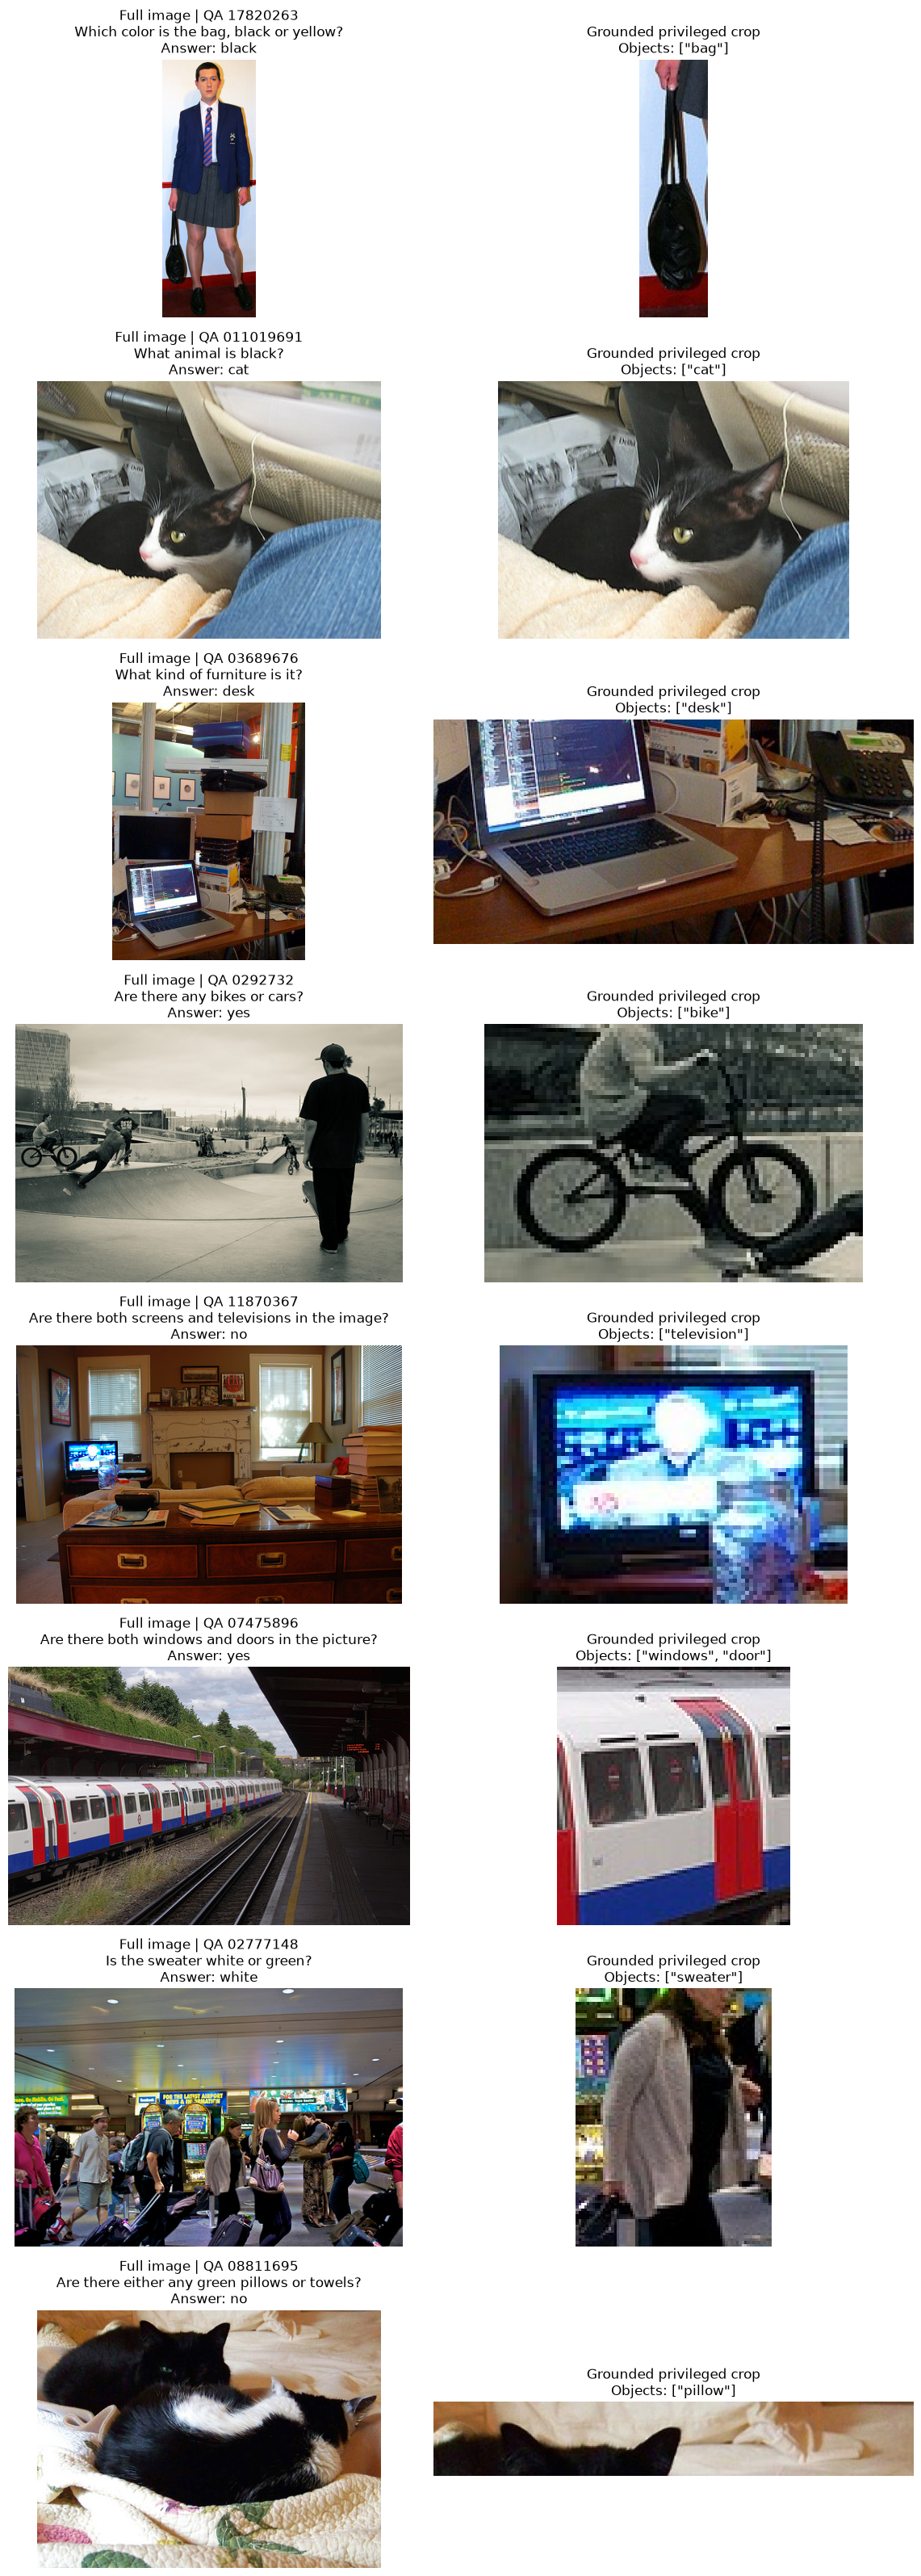

In [41]:
sample = train.sample(
    n=min(8, len(train)),
    random_state=SEED,
)

fig, axes = plt.subplots(
    len(sample),
    2,
    figsize=(12, 4 * len(sample)),
)

if len(sample) == 1:
    axes = np.array([axes])

for ax_row, row in zip(
    axes,
    sample.itertuples(index=False),
):
    with Image.open(row.image_path) as img:
        full = img.convert("RGB")

    with Image.open(row.crop_path) as img:
        crop = img.convert("RGB")

    ax_row[0].imshow(full)
    ax_row[0].set_title(
        f"Full image | QA {row.qa_id}\n"
        f"{row.question}\n"
        f"Answer: {row.answer}"
    )
    ax_row[0].axis("off")

    ax_row[1].imshow(crop)
    ax_row[1].set_title(
        "Grounded privileged crop\n"
        f"Objects: {row.grounded_object_names}"
    )
    ax_row[1].axis("off")

plt.tight_layout()
plt.show()


## Save processed splits and filtering diagnostics

These CSV files keep the same filenames expected by the downstream notebooks. The extra semantic/program/filter columns are additive and should not break Notebooks 02–04.


In [42]:
train_path = PROCESSED / "train.csv"
val_path = PROCESSED / "val.csv"
test_path = PROCESSED / "test.csv"
all_path = PROCESSED / "all_gqa.csv"

filter_diag_path = (
    PROCESSED
    / "crop_filter_diagnostics.csv"
)

train.to_csv(
    train_path,
    index=False,
)

val.to_csv(
    val_path,
    index=False,
)

test.to_csv(
    test_path,
    index=False,
)

final_split.to_csv(
    all_path,
    index=False,
)

filter_reason_counts.to_csv(
    filter_diag_path,
    index=False,
)

summary = {
    "dataset": "GQA",
    "subset": "crop-suitable OPSD subset",
    "target_qa": int(
        len(final_split)
    ),
    "unique_images": int(
        final_split.image_id.nunique()
    ),
    "train_qa": int(
        len(train)
    ),
    "val_qa": int(
        len(val)
    ),
    "test_qa": int(
        len(test)
    ),
    "train_images": int(
        train.image_id.nunique()
    ),
    "val_images": int(
        val.image_id.nunique()
    ),
    "test_images": int(
        test.image_id.nunique()
    ),
    "reuse_downloaded_images_only": bool(
        REUSE_DOWNLOADED_IMAGES_ONLY
    ),
    "unsafe_semantic_types": sorted(
        UNSAFE_SEMANTIC_TYPES
    ),
    "unsafe_structural_types": sorted(
        UNSAFE_STRUCTURAL_TYPES
    ),
    "excluded_detailed_types": sorted(
        EXCLUDED_DETAILED_TYPES
    ),
    "unsafe_program_base_ops": sorted(
        UNSAFE_PROGRAM_BASE_OPS
    ),
    "spatial_text_patterns": (
        SPATIAL_TEXT_PATTERNS
    ),
    "max_grounded_objects": (
        MAX_GROUNDED_OBJECTS
    ),
    "min_crop_area_ratio": (
        MIN_CROP_AREA_RATIO
    ),
    "max_crop_area_ratio": (
        MAX_CROP_AREA_RATIO
    ),
    "max_final_crop_area_ratio": (
        MAX_FINAL_CROP_AREA_RATIO
    ),
    "crop_padding": (
        CROP_PADDING
    ),
    "grounding": (
        "annotations.question + semantic program object IDs; "
        "answer/fullAnswer annotations excluded"
    ),
    "crop_suitability": (
        "GQA semantic/structural/detailed types + "
        "functional-program operation filtering + "
        "spatial-text safety net"
    ),
    "image_source": (
        "Existing local GQA images by default; "
        "official images.zip only for optional top-up"
    ),
}

with open(
    PROCESSED
    / "gqa_dataset_summary.json",
    "w",
) as f:
    json.dump(
        summary,
        f,
        indent=2,
    )

print("Saved:")
print(train_path)
print(val_path)
print(test_path)
print(all_path)
print(filter_diag_path)

print("\nSummary:")
print(
    json.dumps(
        summary,
        indent=2,
    )
)


Saved:
/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/processed/train.csv
/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/processed/val.csv
/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/processed/test.csv
/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/processed/all_gqa.csv
/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/processed/crop_filter_diagnostics.csv

Summary:
{
  "dataset": "GQA",
  "subset": "crop-suitable OPSD subset",
  "target_qa": 5000,
  "unique_images": 2359,
  "train_qa": 3479,
  "val_qa": 753,
  "test_qa": 768,
  "train_images": 1651,
  "val_images": 354,
  "test_images": 354,
  "reuse_downloaded_images_only": true,
  "unsafe_semantic_types": [
    "global",
    "rel",
    "relation"
  ],
  "unsafe_structural_types": [
    "compare"
  ],
  "excluded_detailed_types